# 25 — Final Masked Temporal Fire-Context Anomaly Scoring
## Multi-seed candidate stability after architecture freeze

### Status entering this notebook

The architecture search is **finished**.

NB24C showed that:
- both `T_FIRE` and `ST_FIRE` consistently separate Emerging-3 from Persistent hotspot events;
- spatial context did not provide a reproducible advantage across five random seeds;
- therefore the simpler `T_FIRE` architecture is frozen as the final anomaly model candidate.

This notebook does **not** tune architecture or hyperparameters.

---

## Final scoring principle

For every August cell-day:

1. each of the five frozen `T_FIRE` models reconstructs the masked current-day fire state;
2. reconstruction error is converted to a **within-day percentile rank**;
3. the five ranks are aggregated.

Primary ensemble score:

> **median anomaly rank across 5 seeds**

Primary robust-candidate rule, locked before inspecting locations:

> **ensemble median rank ≥ 0.80 AND at least 4 of 5 seeds individually rank ≥ 0.80**

Stability is additionally reported with:
- number of high-anomaly seeds;
- interquartile range (IQR) across seed ranks;
- minimum and maximum rank.

### Interpretation

A robust candidate is:

> a satellite hotspot cell-day whose current fire state is consistently difficult to reconstruct from its preceding temporal fire context across independently initialized masked models.

It is **not** a label of:
- anthropogenic ignition;
- intentional burning;
- illegal burning;
- plantation clearing;
- or natural ignition.

In [2]:
# 1. Imports

from pathlib import Path
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 320)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("DEVICE:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

DEVICE: cpu


In [3]:
# 2. Resolve project files

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

SEEDS = [11, 22, 33, 44, 55]

for root in candidate_roots:
    data_path = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )

    base_checkpoint = (
        root
        / "model_results"
        / "geomae_spatiotemporal"
        / "t2"
        / "models"
        / "geomae_inspired_encoder.pt"
    )

    model_dir = (
        root
        / "model_results"
        / "geomae_final_robustness"
        / "t2"
        / "models"
    )

    model_paths = [
        model_dir
        / f"T_FIRE_seed{seed}.pt"
        for seed in SEEDS
    ]

    if (
        data_path.exists()
        and base_checkpoint.exists()
        and all(
            p.exists()
            for p in model_paths
        )
    ):
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the regional dataset, NB24 checkpoint, "
        "and all five frozen T_FIRE models from NB24C."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

BASE_CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_spatiotemporal"
    / "t2"
    / "models"
    / "geomae_inspired_encoder.pt"
)

ROBUSTNESS_MODEL_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_final_robustness"
    / "t2"
    / "models"
)

NB23C_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "environmental_context_refinement"
    / "t2"
    / "exports"
    / "august_positive_refined_anomaly.csv"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "final_masked_temporal_anomaly"
    / "t2"
)

EXPORT_DIR = RESULT_DIR / "exports"
FIGURE_DIR = RESULT_DIR / "figures"

for p in [
    EXPORT_DIR,
    FIGURE_DIR,
]:
    p.mkdir(
        parents=True,
        exist_ok=True,
    )

print("PROJECT_ROOT:", PROJECT_ROOT)
print("RESULT_DIR:", RESULT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
RESULT_DIR: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_masked_temporal_anomaly\t2


In [4]:
# 3. Load frozen normalization / temporal settings from NB24

try:
    base_checkpoint = torch.load(
        BASE_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    base_checkpoint = torch.load(
        BASE_CHECKPOINT_PATH,
        map_location="cpu",
    )

TOKEN_FEATURES = list(
    base_checkpoint[
        "token_features"
    ]
)

FEATURE_MEAN = {
    k: float(v)
    for k, v in base_checkpoint[
        "feature_mean"
    ].items()
}

FEATURE_STD = {
    k: float(v)
    for k, v in base_checkpoint[
        "feature_std"
    ].items()
}

TEMPORAL_DAYS = int(
    base_checkpoint[
        "temporal_days"
    ]
)

PRETRAIN_END = pd.Timestamp(
    base_checkpoint[
        "pretrain_end"
    ]
)

MASK_RATIO = float(
    base_checkpoint[
        "mask_ratio"
    ]
)

FIRE_FEATURES = [
    "fire_active",
    "fire_count_log1p",
    "frp_sum_log1p",
]

print("Frozen temporal window:", TEMPORAL_DAYS, "days")
print("Frozen pretraining end:", PRETRAIN_END.date())
print("Frozen fire channels:", FIRE_FEATURES)

Frozen temporal window: 7 days
Frozen pretraining end: 2026-07-31
Frozen fire channels: ['fire_active', 'fire_count_log1p', 'frp_sum_log1p']


In [5]:
# 4. Load dataset

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

df = (
    df
    .sort_values(
        ["cell_id", "date"]
    )
    .reset_index(drop=True)
)

df["fire_count_log1p"] = np.log1p(
    pd.to_numeric(
        df["fire_count"],
        errors="coerce",
    ).clip(lower=0)
)

df["frp_sum_log1p"] = np.log1p(
    pd.to_numeric(
        df["frp_sum"],
        errors="coerce",
    ).clip(lower=0)
)

for feature in FIRE_FEATURES:
    df[
        f"z__{feature}"
    ] = (
        (
            df[feature]
            - FEATURE_MEAN[feature]
        )
        / FEATURE_STD[feature]
    )

Z_FIRE_FEATURES = [
    f"z__{c}"
    for c in FIRE_FEATURES
]

df["fire_token_valid"] = (
    df[Z_FIRE_FEATURES]
    .notna()
    .all(axis=1)
)

print("Rows:", len(df))
print("Nodes:", df["cell_id"].nunique())
print(
    "Date range:",
    df["date"].min().date(),
    "→",
    df["date"].max().date(),
)

Rows: 16625
Nodes: 133
Date range: 2026-05-08 → 2026-09-09


# PART A — Rebuild the frozen `T_FIRE` samples

`T_FIRE` uses only the same grid cell across seven consecutive days.

Each sample contains:

`day t-6, ..., day t`

with three normalized fire channels:

- fire active;
- log(1 + fire count);
- log(1 + FRP).

During anomaly scoring, the current-day (`t`) token is masked.

In [6]:
# 5. Build temporal sequences

records = []

for cell_id, group in df.groupby(
    "cell_id",
    sort=False,
):
    group = (
        group
        .sort_values("date")
        .reset_index(drop=True)
    )

    date_to_pos = {
        pd.Timestamp(d): i
        for i, d in enumerate(
            group["date"]
        )
    }

    for i, row in group.iterrows():
        current_date = pd.Timestamp(
            row["date"]
        )

        required_dates = [
            current_date
            - pd.Timedelta(days=d)
            for d in range(
                TEMPORAL_DAYS - 1,
                -1,
                -1,
            )
        ]

        if not all(
            d in date_to_pos
            for d in required_dates
        ):
            continue

        positions = [
            date_to_pos[d]
            for d in required_dates
        ]

        seq = (
            group.loc[
                positions,
                Z_FIRE_FEATURES,
            ]
            .to_numpy(
                dtype=np.float32
            )
        )

        valid = (
            group.loc[
                positions,
                "fire_token_valid",
            ]
            .to_numpy(
                dtype=bool
            )
        )

        if not valid[-1]:
            continue

        records.append({
            "date": current_date,
            "cell_id": cell_id,
            "grid_lat": float(
                row["grid_lat"]
            ),
            "grid_lon": float(
                row["grid_lon"]
            ),
            "fire_active": float(
                row["fire_active"]
            ),
            "fire_count": float(
                row["fire_count"]
            ),
            "frp_sum": float(
                row["frp_sum"]
            ),
            "sequence": seq,
            "valid": valid,
        })

META = pd.DataFrame(
    [
        {
            k: v
            for k, v in r.items()
            if k not in [
                "sequence",
                "valid",
            ]
        }
        for r in records
    ]
)

X = np.stack(
    [
        r["sequence"]
        for r in records
    ]
).astype(np.float32)

VALID = np.stack(
    [
        r["valid"]
        for r in records
    ]
).astype(bool)

print("Sequence tensor:", X.shape)
print("Metadata rows:", len(META))

Sequence tensor: (15827, 7, 3)
Metadata rows: 15827


In [7]:
# 6. Select August development period

DEV_START = pd.Timestamp("2026-08-01")
DEV_END = pd.Timestamp("2026-08-31")

aug_idx = np.flatnonzero(
    META["date"]
    .between(
        DEV_START,
        DEV_END,
    )
    .to_numpy()
)

print("August samples:", len(aug_idx))

assert len(aug_idx) > 0

August samples: 4123


# PART B — Restore the five frozen `T_FIRE` models

The model architecture must exactly match NB24C.

In [8]:
# 7. Frozen architecture constants

D_MODEL = 48
NHEAD = 4
NUM_LAYERS = 2
DIM_FEEDFORWARD = 96

CENTER_INDEX = TEMPORAL_DAYS - 1
N_FEATURES = len(FIRE_FEATURES)

TOKEN_TIME = list(
    range(TEMPORAL_DAYS)
)

TOKEN_SPACE = [
    0
    for _ in range(
        TEMPORAL_DAYS
    )
]

In [9]:
# 8. Model class matching NB24C

class SmallMaskedTransformer(nn.Module):
    def __init__(
        self,
        n_features=N_FEATURES,
    ):
        super().__init__()

        self.input_proj = nn.Linear(
            n_features,
            D_MODEL,
        )

        self.mask_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                D_MODEL,
            )
        )

        self.time_embedding = nn.Embedding(
            TEMPORAL_DAYS,
            D_MODEL,
        )

        self.space_embedding = nn.Embedding(
            1,
            D_MODEL,
        )

        layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL,
            nhead=NHEAD,
            dim_feedforward=DIM_FEEDFORWARD,
            dropout=0.10,
            batch_first=True,
            norm_first=True,
            activation="gelu",
        )

        self.encoder = nn.TransformerEncoder(
            layer,
            num_layers=NUM_LAYERS,
        )

        self.norm = nn.LayerNorm(
            D_MODEL
        )

        self.reconstruction_head = nn.Linear(
            D_MODEL,
            n_features,
        )

        self.register_buffer(
            "token_time",
            torch.tensor(
                TOKEN_TIME,
                dtype=torch.long,
            ),
            persistent=False,
        )

        self.register_buffer(
            "token_space",
            torch.tensor(
                TOKEN_SPACE,
                dtype=torch.long,
            ),
            persistent=False,
        )

    def forward(
        self,
        x,
        valid_mask,
        mask_positions,
    ):
        h = self.input_proj(x)

        mask_embed = (
            self.mask_token.expand(
                x.shape[0],
                x.shape[1],
                -1,
            )
        )

        h = torch.where(
            mask_positions.unsqueeze(-1),
            mask_embed,
            h,
        )

        h = (
            h
            + self.time_embedding(
                self.token_time
            ).unsqueeze(0)
            + self.space_embedding(
                self.token_space
            ).unsqueeze(0)
        )

        h = self.encoder(
            h,
            src_key_padding_mask=(
                ~valid_mask
            ),
        )

        h = self.norm(h)

        return self.reconstruction_head(
            h
        )

In [10]:
# 9. Load all frozen seed models

MODELS = {}

for seed in SEEDS:
    model_path = (
        ROBUSTNESS_MODEL_DIR
        / f"T_FIRE_seed{seed}.pt"
    )

    try:
        payload = torch.load(
            model_path,
            map_location=DEVICE,
            weights_only=False,
        )
    except TypeError:
        payload = torch.load(
            model_path,
            map_location=DEVICE,
        )

    model = SmallMaskedTransformer().to(
        DEVICE
    )

    model.load_state_dict(
        payload[
            "model_state_dict"
        ],
        strict=True,
    )

    model.eval()

    MODELS[seed] = model

print(
    "Loaded frozen seeds:",
    sorted(MODELS.keys()),
)

Loaded frozen seeds: [11, 22, 33, 44, 55]


# PART C — Score every August cell-day with every seed

In [11]:
# 10. Dataset helper

class TemporalDataset(Dataset):
    def __init__(
        self,
        X,
        valid,
        indices,
    ):
        self.X = X
        self.valid = valid
        self.indices = np.asarray(
            indices
        )

    def __len__(self):
        return len(
            self.indices
        )

    def __getitem__(
        self,
        i,
    ):
        idx = int(
            self.indices[i]
        )

        return (
            torch.from_numpy(
                self.X[idx]
            ),
            torch.from_numpy(
                self.valid[idx]
            ),
            idx,
        )

In [12]:
# 11. Score one frozen model

@torch.no_grad()
def score_seed_model(
    model,
    seed,
    indices,
    batch_size=256,
):
    dataset = TemporalDataset(
        X,
        VALID,
        indices,
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

    rows = []

    model.eval()

    for (
        x_batch,
        valid_batch,
        idx_batch,
    ) in loader:
        x_batch = x_batch.to(
            DEVICE
        )

        valid_batch = valid_batch.to(
            DEVICE
        )

        center_mask = torch.zeros_like(
            valid_batch
        )

        center_mask[
            :,
            CENTER_INDEX,
        ] = True

        center_mask = (
            center_mask
            & valid_batch
        )

        pred = model(
            x_batch,
            valid_batch,
            center_mask,
        )

        true_center = x_batch[
            :,
            CENTER_INDEX,
            :
        ]

        pred_center = pred[
            :,
            CENTER_INDEX,
            :
        ]

        sq_error = (
            pred_center
            - true_center
        ) ** 2

        total_fire_error = (
            sq_error
            .mean(dim=1)
            .detach()
            .cpu()
            .numpy()
        )

        presence_error = (
            sq_error[:, 0]
            .detach()
            .cpu()
            .numpy()
        )

        count_error = (
            sq_error[:, 1]
            .detach()
            .cpu()
            .numpy()
        )

        frp_error = (
            sq_error[:, 2]
            .detach()
            .cpu()
            .numpy()
        )

        pred_np = (
            pred_center
            .detach()
            .cpu()
            .numpy()
        )

        for (
            idx,
            total_e,
            pres_e,
            cnt_e,
            frp_e,
            pred_z,
        ) in zip(
            idx_batch.numpy(),
            total_fire_error,
            presence_error,
            count_error,
            frp_error,
            pred_np,
        ):
            rows.append({
                "sample_index": int(idx),
                f"seed{seed}_error": float(total_e),
                f"seed{seed}_presence_error": float(pres_e),
                f"seed{seed}_count_error": float(cnt_e),
                f"seed{seed}_frp_error": float(frp_e),
                f"seed{seed}_pred_z_active": float(pred_z[0]),
                f"seed{seed}_pred_z_count": float(pred_z[1]),
                f"seed{seed}_pred_z_frp": float(pred_z[2]),
            })

    return pd.DataFrame(
        rows
    )

In [13]:
# 12. Run all five models

seed_score_tables = []

for seed in SEEDS:
    print("Scoring seed", seed)

    score_df = score_seed_model(
        MODELS[seed],
        seed,
        aug_idx,
    )

    seed_score_tables.append(
        score_df
    )

scores = (
    META.iloc[
        aug_idx
    ]
    .reset_index()
    .rename(
        columns={
            "index": "sample_index"
        }
    )
)

for score_df in seed_score_tables:
    scores = (
        scores
        .merge(
            score_df,
            on="sample_index",
            how="left",
            validate="one_to_one",
        )
    )

print("Scored August rows:", len(scores))
display(scores.head())

Scoring seed 11
Scoring seed 22
Scoring seed 33
Scoring seed 44
Scoring seed 55
Scored August rows: 4123


,sample_index,date,cell_id,grid_lat,grid_lon,fire_active,fire_count,frp_sum,seed11_error,seed11_presence_error,seed11_count_error,seed11_frp_error,seed11_pred_z_active,seed11_pred_z_count,seed11_pred_z_frp,seed22_error,seed22_presence_error,seed22_count_error,seed22_frp_error,seed22_pred_z_active,seed22_pred_z_count,seed22_pred_z_frp,seed33_error,seed33_presence_error,seed33_count_error,seed33_frp_error,seed33_pred_z_active,seed33_pred_z_count,seed33_pred_z_frp,seed44_error,seed44_presence_error,seed44_count_error,seed44_frp_error,seed44_pred_z_active,seed44_pred_z_count,seed44_pred_z_frp,seed55_error,seed55_presence_error,seed55_count_error,seed55_frp_error,seed55_pred_z_active,seed55_pred_z_count,seed55_pred_z_frp
0,79,2026-08-01,regional025_10_22,-1.875,113.625,0.0,0.0,0.00,0.002353,0.005946,0.000804,0.000308,-0.198094,-0.216443,-0.227194,0.002193,0.006374,2.183975e-07,0.000204,-0.195369,-0.244328,-0.23049,0.040023,0.048226,0.036155,0.035688,-0.055601,-0.05465,-0.055844,0.001831,0.000005,0.005069,0.000418,-0.2774,-0.315993,-0.265206,0.037561,0.03806,0.042449,0.032175,-0.080115,-0.038764,-0.065383
1,80,2026-08-02,regional025_10_22,-1.875,113.625,0.0,0.0,0.00,0.002353,0.005946,0.000804,0.000308,-0.198094,-0.216443,-0.227194,0.002193,0.006374,2.183975e-07,0.000204,-0.195369,-0.244328,-0.23049,0.040023,0.048226,0.036155,0.035688,-0.055601,-0.05465,-0.055844,0.001831,0.000005,0.005069,0.000418,-0.2774,-0.315993,-0.265206,0.037561,0.03806,0.042449,0.032175,-0.080115,-0.038764,-0.065383
2,81,2026-08-03,regional025_10_22,-1.875,113.625,0.0,0.0,0.00,0.002353,0.005946,0.000804,0.000308,-0.198094,-0.216443,-0.227194,0.002193,0.006374,2.183975e-07,0.000204,-0.195369,-0.244328,-0.23049,0.040023,0.048226,0.036155,0.035688,-0.055601,-0.05465,-0.055844,0.001831,0.000005,0.005069,0.000418,-0.2774,-0.315993,-0.265206,0.037561,0.03806,0.042449,0.032175,-0.080115,-0.038764,-0.065383
3,82,2026-08-04,regional025_10_22,-1.875,113.625,0.0,0.0,0.00,0.002353,0.005946,0.000804,0.000308,-0.198094,-0.216443,-0.227194,0.002193,0.006374,2.183975e-07,0.000204,-0.195369,-0.244328,-0.23049,0.040023,0.048226,0.036155,0.035688,-0.055601,-0.05465,-0.055844,0.001831,0.000005,0.005069,0.000418,-0.2774,-0.315993,-0.265206,0.037561,0.03806,0.042449,0.032175,-0.080115,-0.038764,-0.065383
4,83,2026-08-05,regional025_10_22,-1.875,113.625,1.0,3.0,8.44,15.423821,14.679817,17.192345,14.399304,-0.198094,-0.216443,-0.227194,15.502547,14.658944,1.742436e+01,14.424332,-0.195369,-0.244328,-0.23049,14.204425,13.608217,15.876816,13.128240,-0.055601,-0.05465,-0.055844,16.003614,15.293814,18.027798,14.689231,-0.2774,-0.315993,-0.265206,14.245870,13.78968,15.750467,13.197460,-0.080115,-0.038764,-0.065383


In [14]:
# 13. Convert each seed's error into within-day percentile rank

for seed in SEEDS:
    error_col = (
        f"seed{seed}_error"
    )

    rank_col = (
        f"seed{seed}_rank"
    )

    scores[
        rank_col
    ] = (
        scores
        .groupby(
            "date"
        )[error_col]
        .rank(
            pct=True,
            ascending=True,
            method="average",
        )
    )

RANK_COLS = [
    f"seed{seed}_rank"
    for seed in SEEDS
]

display(
    scores[
        [
            "date",
            "cell_id",
            "fire_active",
            *RANK_COLS,
        ]
    ].head()
)

,date,cell_id,fire_active,seed11_rank,seed22_rank,seed33_rank,seed44_rank,seed55_rank
0,2026-08-01,regional025_10_22,0.0,0.225564,0.225564,0.225564,0.225564,0.225564
1,2026-08-02,regional025_10_22,0.0,0.248120,0.248120,0.248120,0.248120,0.248120
2,2026-08-03,regional025_10_22,0.0,0.251880,0.251880,0.251880,0.251880,0.251880
3,2026-08-04,regional025_10_22,0.0,0.244361,0.244361,0.244361,0.244361,0.244361
4,2026-08-05,regional025_10_22,1.0,0.894737,0.894737,0.864662,0.887218,0.872180


# PART D — Locked ensemble score and robust-candidate rule

Primary score:

`median(seed11_rank, seed22_rank, seed33_rank, seed44_rank, seed55_rank)`

Locked high-anomaly threshold:

`rank >= 0.80`

Locked robust agreement:

`at least 4 / 5 seeds high`

Primary robust candidate:

`actual hotspot AND median >= 0.80 AND high-seed-count >= 4`

In [15]:
# 14. Ensemble stability metrics

PRIMARY_THRESHOLD = 0.80
REQUIRED_HIGH_SEEDS = 4

rank_matrix = (
    scores[
        RANK_COLS
    ]
    .to_numpy(
        dtype=float
    )
)

scores[
    "ensemble_median_rank"
] = np.nanmedian(
    rank_matrix,
    axis=1,
)

scores[
    "ensemble_mean_rank"
] = np.nanmean(
    rank_matrix,
    axis=1,
)

scores[
    "ensemble_min_rank"
] = np.nanmin(
    rank_matrix,
    axis=1,
)

scores[
    "ensemble_max_rank"
] = np.nanmax(
    rank_matrix,
    axis=1,
)

scores[
    "ensemble_rank_iqr"
] = (
    np.nanpercentile(
        rank_matrix,
        75,
        axis=1,
    )
    -
    np.nanpercentile(
        rank_matrix,
        25,
        axis=1,
    )
)

scores[
    "high_seed_count"
] = (
    rank_matrix
    >= PRIMARY_THRESHOLD
).sum(
    axis=1
)

scores[
    "high_seed_fraction"
] = (
    scores[
        "high_seed_count"
    ]
    / len(SEEDS)
)

scores[
    "robust_high_anomaly"
] = (
    (
        scores[
            "ensemble_median_rank"
        ]
        >= PRIMARY_THRESHOLD
    )
    &
    (
        scores[
            "high_seed_count"
        ]
        >= REQUIRED_HIGH_SEEDS
    )
)

scores[
    "robust_anomaly_candidate"
] = (
    scores[
        "fire_active"
    ].eq(1)
    &
    scores[
        "robust_high_anomaly"
    ]
)

print(
    "All August cell-days:",
    len(scores),
)

print(
    "Actual hotspot cell-days:",
    int(
        scores[
            "fire_active"
        ].eq(1)
        .sum()
    ),
)

print(
    "Robust hotspot anomaly candidates:",
    int(
        scores[
            "robust_anomaly_candidate"
        ].sum()
    ),
)

All August cell-days: 4123
Actual hotspot cell-days: 2106
Robust hotspot anomaly candidates: 620


In [16]:
# 15. Final candidate table

candidates = (
    scores[
        scores[
            "robust_anomaly_candidate"
        ]
    ]
    .copy()
    .sort_values(
        [
            "ensemble_median_rank",
            "high_seed_count",
            "ensemble_rank_iqr",
        ],
        ascending=[
            False,
            False,
            True,
        ],
    )
)

candidate_display_cols = [
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "fire_count",
    "frp_sum",
    *RANK_COLS,
    "ensemble_median_rank",
    "ensemble_rank_iqr",
    "high_seed_count",
]

display(
    candidates[
        candidate_display_cols
    ].head(50)
)

,date,cell_id,grid_lat,grid_lon,fire_count,frp_sum,seed11_rank,seed22_rank,seed33_rank,seed44_rank,seed55_rank,ensemble_median_rank,ensemble_rank_iqr,high_seed_count
676,2026-08-26,regional025_11_31,-1.625,115.875,10.0,186.34,1.000000,0.984962,1.000000,1.000000,1.000000,1.000000,0.000000,5
787,2026-08-13,regional025_12_23,-1.375,113.875,7.0,60.44,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,5
1439,2026-08-14,regional025_13_31,-1.125,115.875,3.0,19.59,1.000000,1.000000,0.992481,1.000000,1.000000,1.000000,0.000000,5
1623,2026-08-12,regional025_2_26,-3.875,114.625,8.0,119.67,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,5
1736,2026-08-01,regional025_3_26,-3.625,114.625,5.0,18.50,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,5
1937,2026-08-16,regional025_4_22,-3.375,113.625,12.0,156.30,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,5
2052,2026-08-07,regional025_4_26,-3.375,114.625,6.0,26.73,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,5
2521,2026-08-11,regional025_5_30,-3.125,115.625,5.0,243.28,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,5
2742,2026-08-15,regional025_6_26,-2.875,114.625,9.0,191.86,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,5
3229,2026-08-06,regional025_7_30,-2.625,115.625,1.0,114.58,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,5


# PART E — Candidate stability and threshold sensitivity

The primary threshold remains `0.80 + 4/5 seeds`.

Sensitivity analysis is descriptive only.
It does not replace the locked primary rule after seeing the result.

In [17]:
# 16. Sensitivity table

sensitivity_rows = []

for threshold in [
    0.75,
    0.80,
    0.85,
    0.90,
]:
    temp_high = (
        rank_matrix
        >= threshold
    )

    high_counts = (
        temp_high.sum(
            axis=1
        )
    )

    med = np.nanmedian(
        rank_matrix,
        axis=1,
    )

    hotspot = (
        scores[
            "fire_active"
        ].eq(1)
        .to_numpy()
    )

    for required in [
        3,
        4,
        5,
    ]:
        candidate_mask = (
            hotspot
            &
            (
                med
                >= threshold
            )
            &
            (
                high_counts
                >= required
            )
        )

        sensitivity_rows.append({
            "threshold": threshold,
            "required_high_seeds": required,
            "candidate_count": int(
                candidate_mask.sum()
            ),
        })

sensitivity = pd.DataFrame(
    sensitivity_rows
)

display(sensitivity)

,threshold,required_high_seeds,candidate_count
0,0.75,3,849
1,0.75,4,800
2,0.75,5,684
3,0.80,3,667
4,0.80,4,620
5,0.80,5,530
6,0.85,3,499
7,0.85,4,459
8,0.85,5,378
9,0.90,3,348


In [18]:
# 17. Agreement distribution among actual hotspots

hotspots = (
    scores[
        scores[
            "fire_active"
        ].eq(1)
    ]
    .copy()
)

agreement_distribution = (
    hotspots[
        "high_seed_count"
    ]
    .value_counts()
    .sort_index()
    .rename_axis(
        "high_seed_count"
    )
    .reset_index(
        name="hotspot_events"
    )
)

display(
    agreement_distribution
)

,high_seed_count,hotspot_events
0,0,1325
1,1,62
2,2,52
3,3,47
4,4,90
5,5,530


# PART F — Merge previous research groups / history anomaly

These variables are used only for interpretation.

They are not used to define the final ensemble score.

In [19]:
# 18. Merge NB23C information if available

candidate_analysis = (
    hotspots.copy()
)

if NB23C_PATH.exists():
    nb23c = pd.read_csv(
        NB23C_PATH,
        parse_dates=[
            "date",
            "event_date",
        ],
    )

    merge_cols = [
        "event_date",
        "cell_id",
        "research_group",
    ]

    optional_cols = [
        "history_anomaly_day_rank",
        "env_rank__E2_ANTECEDENT_LAND_LR",
        "env_rank__E3_ANTECEDENT_LAND_HGB",
        "robust_joint_high",
    ]

    for col in optional_cols:
        if col in nb23c.columns:
            merge_cols.append(col)

    candidate_analysis = (
        hotspots
        .rename(
            columns={
                "date": "event_date"
            }
        )
        .merge(
            nb23c[
                merge_cols
            ],
            on=[
                "event_date",
                "cell_id",
            ],
            how="left",
        )
    )

    print(
        candidate_analysis[
            "research_group"
        ].value_counts(
            dropna=False
        )
    )
else:
    print(
        "NB23C export not found; "
        "group interpretation skipped."
    )

research_group
Persistent    1849
Emerging-3     217
NaN             40
Name: count, dtype: int64


In [20]:
# 19. Candidate composition by research group

if (
    "research_group"
    in candidate_analysis.columns
):
    candidate_group_summary = (
        candidate_analysis
        .groupby(
            [
                "research_group",
                "robust_anomaly_candidate",
            ],
            dropna=False,
        )
        .size()
        .rename(
            "events"
        )
        .reset_index()
    )

    display(
        candidate_group_summary
    )

    group_rank_summary = (
        candidate_analysis
        .groupby(
            "research_group",
            dropna=False,
        )
        .agg(
            events=(
                "cell_id",
                "size",
            ),
            median_ensemble_rank=(
                "ensemble_median_rank",
                "median",
            ),
            mean_ensemble_rank=(
                "ensemble_median_rank",
                "mean",
            ),
            robust_candidates=(
                "robust_anomaly_candidate",
                "sum",
            ),
        )
        .reset_index()
    )

    display(
        group_rank_summary
    )

,research_group,robust_anomaly_candidate,events
0,Emerging-3,False,99
1,Emerging-3,True,118
2,Persistent,False,1373
3,Persistent,True,476
4,NaN,False,14
5,NaN,True,26


,research_group,events,median_ensemble_rank,mean_ensemble_rank,robust_candidates
0,Emerging-3,217,0.827068,0.814975,118
1,Persistent,1849,0.646617,0.634852,476
2,NaN,40,0.857143,0.838346,26


In [21]:
# 20. Overlap with history anomaly

history_overlap_summary = pd.DataFrame()

if (
    "history_anomaly_day_rank"
    in candidate_analysis.columns
):
    candidate_analysis[
        "history_high_080"
    ] = (
        candidate_analysis[
            "history_anomaly_day_rank"
        ]
        >= 0.80
    )

    candidate_analysis[
        "ensemble_high_080"
    ] = (
        candidate_analysis[
            "ensemble_median_rank"
        ]
        >= 0.80
    )

    both = int(
        (
            candidate_analysis[
                "robust_anomaly_candidate"
            ]
            &
            candidate_analysis[
                "history_high_080"
            ]
        ).sum()
    )

    robust_n = int(
        candidate_analysis[
            "robust_anomaly_candidate"
        ].sum()
    )

    history_n = int(
        candidate_analysis[
            "history_high_080"
        ].sum()
    )

    union = int(
        (
            candidate_analysis[
                "robust_anomaly_candidate"
            ]
            |
            candidate_analysis[
                "history_high_080"
            ]
        ).sum()
    )

    jaccard = (
        both / union
        if union
        else np.nan
    )

    history_overlap_summary = pd.DataFrame({
        "robust_model_candidates": [
            robust_n
        ],
        "history_high_events": [
            history_n
        ],
        "intersection": [
            both
        ],
        "union": [
            union
        ],
        "jaccard": [
            jaccard
        ],
    })

    display(
        history_overlap_summary
    )

,robust_model_candidates,history_high_events,intersection,union,jaccard
0,620,125,68,677,0.100443


# PART G — Spatial and temporal concentration audit

A useful candidate list should not be driven by one cell or one date only.

In [22]:
# 21. Cell concentration

candidate_cell_concentration = (
    candidates
    .groupby(
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
        ]
    )
    .size()
    .rename(
        "candidate_events"
    )
    .reset_index()
    .sort_values(
        "candidate_events",
        ascending=False,
    )
)

display(
    candidate_cell_concentration.head(20)
)

if len(candidates):
    top5_cell_share = (
        candidate_cell_concentration[
            "candidate_events"
        ]
        .head(5)
        .sum()
        / len(candidates)
    )
else:
    top5_cell_share = np.nan

print(
    "Top-5-cell candidate share:",
    round(
        float(
            top5_cell_share
        ),
        4,
    )
    if np.isfinite(
        top5_cell_share
    )
    else np.nan,
)

,cell_id,grid_lat,grid_lon,candidate_events
101,regional025_8_24,-2.375,114.125,21
113,regional025_9_23,-2.125,113.875,21
94,regional025_7_28,-2.625,115.125,19
84,regional025_6_28,-2.875,115.125,19
114,regional025_9_24,-2.125,114.125,18
100,regional025_8_23,-2.375,113.875,16
73,regional025_5_28,-3.125,115.125,14
115,regional025_9_25,-2.125,114.375,13
25,regional025_12_24,-1.375,114.125,12
62,regional025_4_27,-3.375,114.875,11


Top-5-cell candidate share: 0.1581


In [23]:
# 22. Date concentration

candidate_date_concentration = (
    candidates
    .groupby(
        "date"
    )
    .size()
    .rename(
        "candidate_events"
    )
    .reset_index()
    .sort_values(
        "date"
    )
)

display(
    candidate_date_concentration
)

,date,candidate_events
0,2026-08-01,26
1,2026-08-02,21
2,2026-08-04,18
3,2026-08-05,24
4,2026-08-06,25
5,2026-08-07,25
6,2026-08-08,23
7,2026-08-09,20
8,2026-08-10,25
9,2026-08-11,24


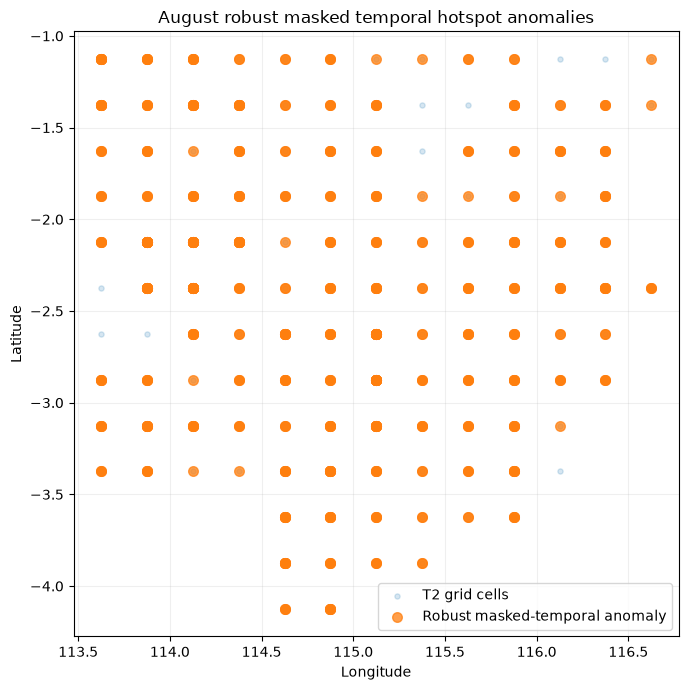

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_masked_temporal_anomaly\t2\figures\01_final_candidate_map.png


In [24]:
# 23. Candidate map

fig, ax = plt.subplots(
    figsize=(8, 7)
)

nodes = (
    scores[
        [
            "cell_id",
            "grid_lon",
            "grid_lat",
        ]
    ]
    .drop_duplicates()
)

ax.scatter(
    nodes[
        "grid_lon"
    ],
    nodes[
        "grid_lat"
    ],
    s=14,
    alpha=0.18,
    label="T2 grid cells",
)

if len(candidates):
    ax.scatter(
        candidates[
            "grid_lon"
        ],
        candidates[
            "grid_lat"
        ],
        s=48,
        alpha=0.75,
        label="Robust masked-temporal anomaly",
    )

ax.set_xlabel(
    "Longitude"
)

ax.set_ylabel(
    "Latitude"
)

ax.set_title(
    "August robust masked temporal hotspot anomalies"
)

ax.set_aspect(
    "equal",
    adjustable="box",
)

ax.grid(
    alpha=0.2
)

ax.legend()

plt.tight_layout()

map_path = (
    FIGURE_DIR
    / "01_final_candidate_map.png"
)

plt.savefig(
    map_path,
    dpi=190,
    bbox_inches="tight",
)

plt.show()

print("Saved:", map_path)

# PART H — Case-study visualization

For the strongest candidates, show the previous six days of actual fire activity at the same cell.

This is intentionally descriptive.

It helps answer:

> What did the temporal context look like immediately before the anomalous hotspot?

In [25]:
# 24. Select strongest case-study candidates

N_CASES = min(
    10,
    len(candidates),
)

case_studies = (
    candidates
    .head(
        N_CASES
    )
    .copy()
)

display(
    case_studies[
        [
            "date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "fire_count",
            "frp_sum",
            "ensemble_median_rank",
            "high_seed_count",
            "ensemble_rank_iqr",
        ]
    ]
)

,date,cell_id,grid_lat,grid_lon,fire_count,frp_sum,ensemble_median_rank,high_seed_count,ensemble_rank_iqr
676,2026-08-26,regional025_11_31,-1.625,115.875,10.0,186.34,1.0,5,0.0
787,2026-08-13,regional025_12_23,-1.375,113.875,7.0,60.44,1.0,5,0.0
1439,2026-08-14,regional025_13_31,-1.125,115.875,3.0,19.59,1.0,5,0.0
1623,2026-08-12,regional025_2_26,-3.875,114.625,8.0,119.67,1.0,5,0.0
1736,2026-08-01,regional025_3_26,-3.625,114.625,5.0,18.50,1.0,5,0.0
1937,2026-08-16,regional025_4_22,-3.375,113.625,12.0,156.30,1.0,5,0.0
2052,2026-08-07,regional025_4_26,-3.375,114.625,6.0,26.73,1.0,5,0.0
2521,2026-08-11,regional025_5_30,-3.125,115.625,5.0,243.28,1.0,5,0.0
2742,2026-08-15,regional025_6_26,-2.875,114.625,9.0,191.86,1.0,5,0.0
3229,2026-08-06,regional025_7_30,-2.625,115.625,1.0,114.58,1.0,5,0.0


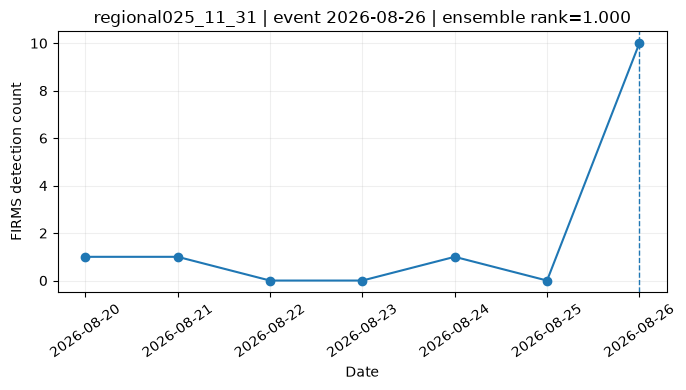

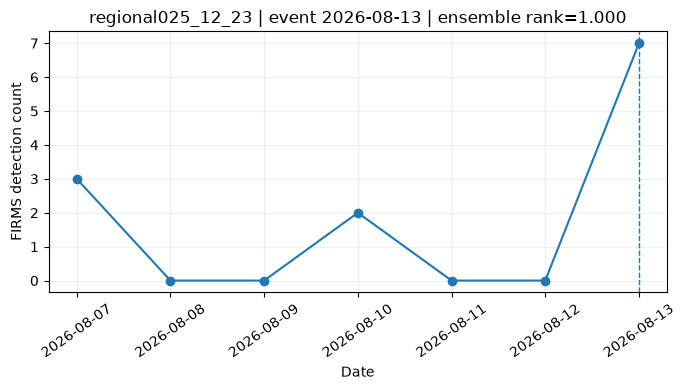

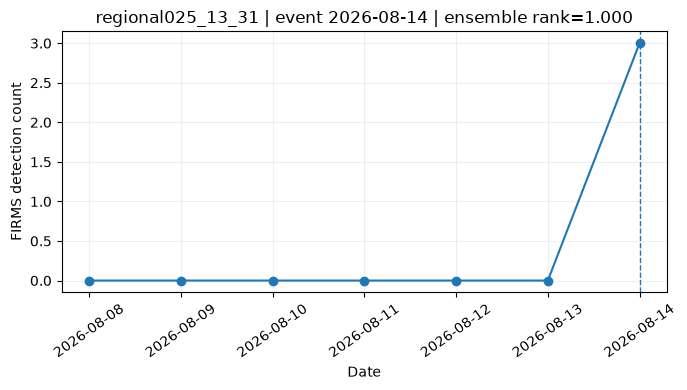

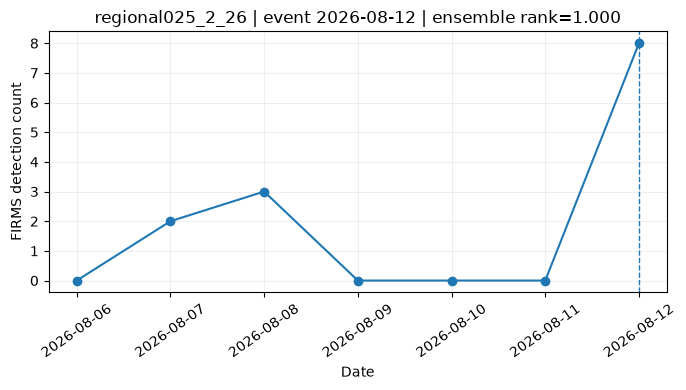

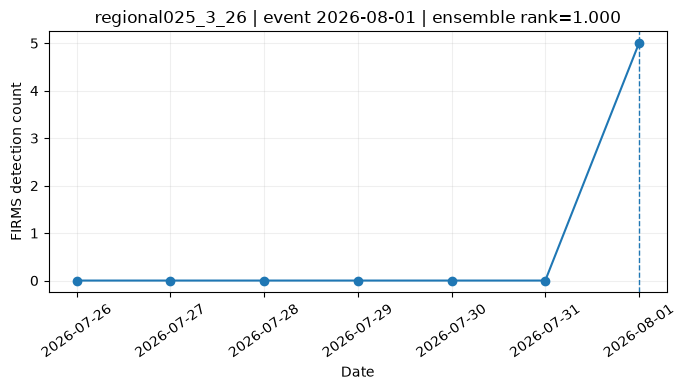

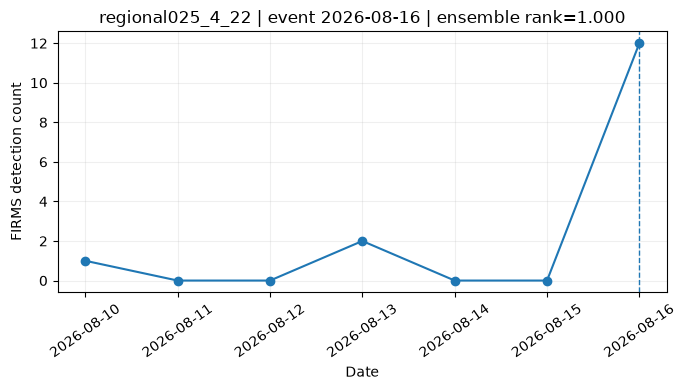

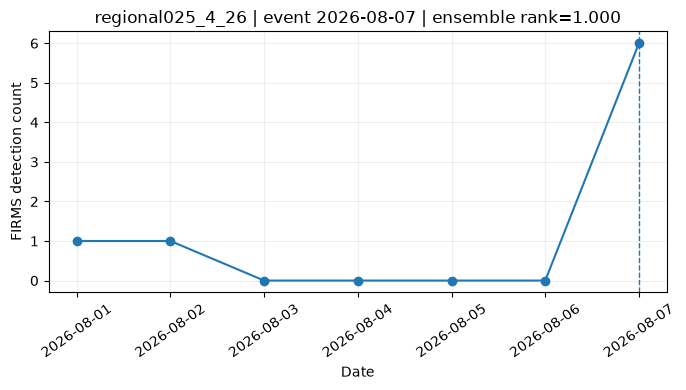

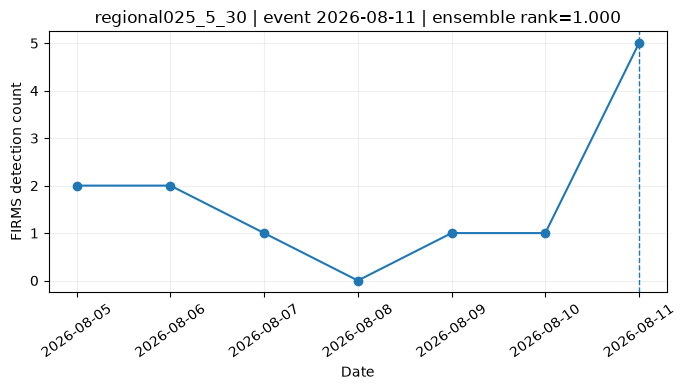

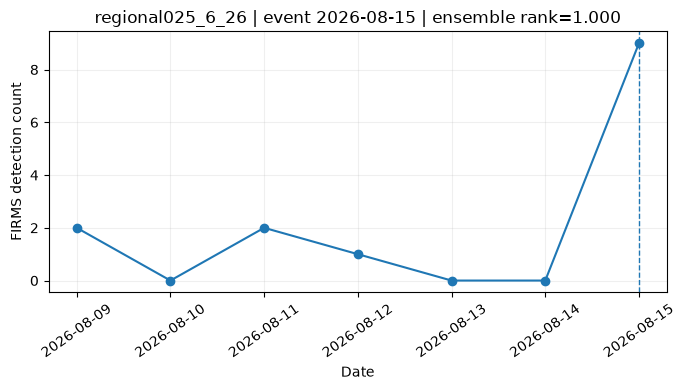

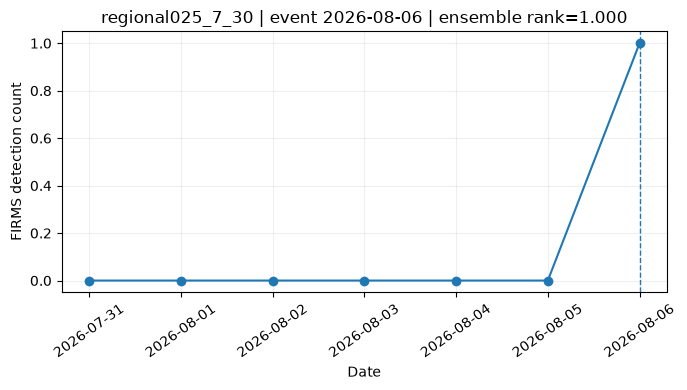

In [26]:
# 25. Plot temporal fire-count profile for each strongest candidate

for row in case_studies.itertuples(
    index=False
):
    start_date = (
        pd.Timestamp(
            row.date
        )
        - pd.Timedelta(
            days=TEMPORAL_DAYS - 1
        )
    )

    temp = (
        df[
            df[
                "cell_id"
            ].eq(
                row.cell_id
            )
            &
            df[
                "date"
            ].between(
                start_date,
                row.date,
            )
        ][
            [
                "date",
                "fire_count",
                "frp_sum",
            ]
        ]
        .sort_values(
            "date"
        )
    )

    fig, ax = plt.subplots(
        figsize=(7, 4)
    )

    ax.plot(
        temp[
            "date"
        ],
        temp[
            "fire_count"
        ],
        marker="o",
    )

    ax.axvline(
        pd.Timestamp(
            row.date
        ),
        linestyle="--",
        linewidth=1,
    )

    ax.set_xlabel(
        "Date"
    )

    ax.set_ylabel(
        "FIRMS detection count"
    )

    ax.set_title(
        f"{row.cell_id} | event {pd.Timestamp(row.date).date()} | "
        f"ensemble rank={row.ensemble_median_rank:.3f}"
    )

    ax.grid(
        alpha=0.2
    )

    plt.xticks(
        rotation=35
    )

    plt.tight_layout()

    safe_date = (
        pd.Timestamp(
            row.date
        )
        .strftime(
            "%Y%m%d"
        )
    )

    fig_path = (
        FIGURE_DIR
        / f"case_{safe_date}_{row.cell_id}.png"
    )

    plt.savefig(
        fig_path,
        dpi=170,
        bbox_inches="tight",
    )

    plt.show()

# PART I — Ensemble reconstruction expectation

For interpretation only, average each seed's reconstructed normalized current fire state.

This is NOT a probability prediction.

It is the model ensemble's reconstructed current fire state in the normalized feature space.

In [27]:
# 26. Ensemble reconstructed center values

for target_name, suffix in [
    (
        "active",
        "pred_z_active",
    ),
    (
        "count",
        "pred_z_count",
    ),
    (
        "frp",
        "pred_z_frp",
    ),
]:
    pred_cols = [
        f"seed{seed}_{suffix}"
        for seed in SEEDS
    ]

    scores[
        f"ensemble_pred_z_{target_name}"
    ] = (
        scores[
            pred_cols
        ]
        .median(
            axis=1
        )
    )

scores[
    "ensemble_pred_fire_active_rawscale"
] = (
    scores[
        "ensemble_pred_z_active"
    ]
    * FEATURE_STD[
        "fire_active"
    ]
    + FEATURE_MEAN[
        "fire_active"
    ]
)

scores[
    "ensemble_pred_log_count_rawscale"
] = (
    scores[
        "ensemble_pred_z_count"
    ]
    * FEATURE_STD[
        "fire_count_log1p"
    ]
    + FEATURE_MEAN[
        "fire_count_log1p"
    ]
)

scores[
    "ensemble_pred_log_frp_rawscale"
] = (
    scores[
        "ensemble_pred_z_frp"
    ]
    * FEATURE_STD[
        "frp_sum_log1p"
    ]
    + FEATURE_MEAN[
        "frp_sum_log1p"
    ]
)

scores[
    "ensemble_pred_fire_count_approx"
] = np.expm1(
    scores[
        "ensemble_pred_log_count_rawscale"
    ]
).clip(lower=0)

scores[
    "ensemble_pred_frp_sum_approx"
] = np.expm1(
    scores[
        "ensemble_pred_log_frp_rawscale"
    ]
).clip(lower=0)

candidate_expectation = (
    scores[
        scores[
            "robust_anomaly_candidate"
        ]
    ][
        [
            "date",
            "cell_id",
            "fire_count",
            "frp_sum",
            "ensemble_pred_fire_active_rawscale",
            "ensemble_pred_fire_count_approx",
            "ensemble_pred_frp_sum_approx",
            "ensemble_median_rank",
            "high_seed_count",
        ]
    ]
    .sort_values(
        "ensemble_median_rank",
        ascending=False,
    )
)

display(
    candidate_expectation.head(30)
)

,date,cell_id,fire_count,frp_sum,ensemble_pred_fire_active_rawscale,ensemble_pred_fire_count_approx,ensemble_pred_frp_sum_approx,ensemble_median_rank,high_seed_count
3841,2026-08-29,regional025_9_24,300.0,3329.40,0.693475,5.310529,17.422730,1.0,5
3837,2026-08-25,regional025_9_24,82.0,692.28,0.713376,5.380710,17.461528,1.0,5
3839,2026-08-27,regional025_9_24,133.0,1618.34,0.712494,5.362876,17.449754,1.0,5
3840,2026-08-28,regional025_9_24,304.0,6574.99,0.707668,5.349335,17.480423,1.0,5
3836,2026-08-24,regional025_9_24,101.0,606.65,0.714653,5.400881,17.527015,1.0,5
3804,2026-08-23,regional025_9_23,79.0,149.82,0.703372,5.357633,17.025033,1.0,5
3801,2026-08-20,regional025_9_23,105.0,566.84,0.720120,5.360220,17.330563,1.0,5
3802,2026-08-21,regional025_9_23,87.0,401.90,0.709277,5.354380,17.195311,1.0,5
3800,2026-08-19,regional025_9_23,168.0,806.94,0.729315,5.388742,17.425399,1.0,5
3811,2026-08-30,regional025_9_23,234.0,896.38,0.694947,5.299245,16.668779,1.0,5


# PART J — Export final development-period artifacts

In [28]:
# 27. Save outputs

ALL_SCORES_PATH = (
    EXPORT_DIR
    / "august_all_cells_multiseed_scores.csv"
)

HOTSPOT_SCORES_PATH = (
    EXPORT_DIR
    / "august_hotspot_multiseed_scores.csv"
)

FINAL_CANDIDATES_PATH = (
    EXPORT_DIR
    / "august_final_robust_anomaly_candidates.csv"
)

SENSITIVITY_PATH = (
    EXPORT_DIR
    / "candidate_threshold_sensitivity.csv"
)

AGREEMENT_PATH = (
    EXPORT_DIR
    / "hotspot_seed_agreement_distribution.csv"
)

CELL_CONC_PATH = (
    EXPORT_DIR
    / "candidate_cell_concentration.csv"
)

DATE_CONC_PATH = (
    EXPORT_DIR
    / "candidate_date_concentration.csv"
)

EXPECTATION_PATH = (
    EXPORT_DIR
    / "candidate_reconstruction_expectation.csv"
)

METADATA_PATH = (
    EXPORT_DIR
    / "nb25_final_scoring_metadata.json"
)

scores.to_csv(
    ALL_SCORES_PATH,
    index=False,
)

hotspots.to_csv(
    HOTSPOT_SCORES_PATH,
    index=False,
)

candidate_analysis.to_csv(
    EXPORT_DIR
    / "august_hotspot_candidate_analysis.csv",
    index=False,
)

candidates.to_csv(
    FINAL_CANDIDATES_PATH,
    index=False,
)

sensitivity.to_csv(
    SENSITIVITY_PATH,
    index=False,
)

agreement_distribution.to_csv(
    AGREEMENT_PATH,
    index=False,
)

candidate_cell_concentration.to_csv(
    CELL_CONC_PATH,
    index=False,
)

candidate_date_concentration.to_csv(
    DATE_CONC_PATH,
    index=False,
)

candidate_expectation.to_csv(
    EXPECTATION_PATH,
    index=False,
)

if len(
    history_overlap_summary
):
    history_overlap_summary.to_csv(
        EXPORT_DIR
        / "history_overlap_summary.csv",
        index=False,
    )

metadata = {
    "notebook": "25_final_masked_temporal_anomaly_scoring",
    "frozen_architecture": "T_FIRE",
    "seeds": SEEDS,
    "temporal_days": TEMPORAL_DAYS,
    "primary_score": "median within-day reconstruction-error rank across five seeds",
    "primary_threshold": PRIMARY_THRESHOLD,
    "required_high_seeds": REQUIRED_HIGH_SEEDS,
    "candidate_definition": (
        "actual hotspot AND ensemble_median_rank >= 0.80 "
        "AND at least 4 of 5 seeds rank >= 0.80"
    ),
    "development_period": "August 2026",
    "architecture_tuning_in_this_notebook": False,
    "important_limit": (
        "Candidates are contextual hotspot anomalies, not ignition-cause labels."
    ),
}

METADATA_PATH.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("Saved outputs to:", EXPORT_DIR)

Saved outputs to: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_masked_temporal_anomaly\t2\exports


In [29]:
# 28. Final automatic review

print("=== NB25 FINAL ANOMALY REVIEW ===")
print()

print(
    "Actual August hotspot cell-days:",
    len(hotspots),
)

print(
    "Robust anomaly candidates:",
    len(candidates),
)

print(
    "Candidate rate among hotspot cell-days:",
    round(
        (
            len(candidates)
            / len(hotspots)
        )
        if len(hotspots)
        else np.nan,
        4,
    ),
)

print(
    "Median candidate ensemble rank:",
    round(
        float(
            candidates[
                "ensemble_median_rank"
            ].median()
        ),
        4,
    )
    if len(candidates)
    else np.nan,
)

print(
    "Median candidate rank IQR:",
    round(
        float(
            candidates[
                "ensemble_rank_iqr"
            ].median()
        ),
        4,
    )
    if len(candidates)
    else np.nan,
)

print(
    "Top-5-cell candidate share:",
    round(
        float(
            top5_cell_share
        ),
        4,
    )
    if np.isfinite(
        top5_cell_share
    )
    else np.nan,
)

if (
    "research_group"
    in candidate_analysis.columns
):
    print()
    print(
        "Candidate research-group composition:"
    )

    display(
        candidate_analysis[
            candidate_analysis[
                "robust_anomaly_candidate"
            ]
        ][
            "research_group"
        ]
        .value_counts(
            dropna=False
        )
        .rename_axis(
            "research_group"
        )
        .reset_index(
            name="candidates"
        )
    )

if len(
    history_overlap_summary
):
    print()
    print(
        "Overlap with history anomaly:"
    )

    display(
        history_overlap_summary
    )

print()
print(
    "Primary rule remains locked at median >= 0.80 and >= 4/5 high seeds."
)

print(
    "Do not change the threshold because of candidate count or location."
)

=== NB25 FINAL ANOMALY REVIEW ===

Actual August hotspot cell-days: 2106
Robust anomaly candidates: 620
Candidate rate among hotspot cell-days: 0.2944
Median candidate ensemble rank: 0.9098
Median candidate rank IQR: 0.015
Top-5-cell candidate share: 0.1581

Candidate research-group composition:


,research_group,candidates
0,Persistent,476
1,Emerging-3,118
2,NaN,26



Overlap with history anomaly:


,robust_model_candidates,history_high_events,intersection,union,jaccard
0,620,125,68,677,0.100443



Primary rule remains locked at median >= 0.80 and >= 4/5 high seeds.
Do not change the threshold because of candidate count or location.


# What to send back

After **Run All**, send the executed NB25 notebook.

The most important outputs are:

1. number of robust anomaly candidates;
2. candidate rate among August hotspot cell-days;
3. distribution of 0–5 high-seed agreement;
4. candidate composition: Emerging-3 vs Persistent;
5. overlap with hand-crafted history anomaly;
6. top-5-cell concentration;
7. threshold sensitivity table;
8. strongest candidate case-study plots.

After reviewing NB25, the next step should be to freeze the final candidate list and prepare:
- thesis figures;
- methodology wording;
- results tables;
- and a clearly labeled secondary chronological evaluation.